In [1]:
from sklearn.datasets import load_diabetes

import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
from sklearn.model_selection import train_test_split

In [3]:
X,y = load_diabetes(return_X_y=True)

In [4]:
print(X.shape)
print(y.shape)


(442, 10)
(442,)


In [5]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=2)

In [6]:
reg = LinearRegression()
reg.fit(X_train,y_train)


,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [7]:
print(reg.coef_)
print(reg.intercept_)

[  -9.15865318 -205.45432163  516.69374454  340.61999905 -895.5520019
  561.22067904  153.89310954  126.73139688  861.12700152   52.42112238]
151.88331005254167


In [8]:
y_pred = reg.predict(X_test)
r2_score(y_test,y_pred)


0.4399338661568969

In [142]:

class MBGDRegressor:
    def __init__(self,batch_size,learning_rate=0.01,epochs=100):
        self.coef_ = None
        self.intercept_ = None
        self.lr = learning_rate
        self.epochs = epochs 
        self.batch_size = batch_size
    def fit(self,X_train,y_train):
        #initialize ur coeffs 
        self.intercept_ = 0
        self.coef_ = np.ones(X_train.shape[1])

        for i in range(self.epochs):

            for j in range(int(X_train.shape[0]/self.batch_size)):
                    #update all the coeffs and the intercept
                    idx=random.sample(range(X_train.shape[0]),self.batch_size)
                    y_hat = np.dot(X_train[idx],self.coef_) + self.intercept_ 
                    #print("Shape of y_hat",y_hat.shape)
                    intercept_der = -2 * np.mean(y_train[idx] - y_hat   )
                    self.intercept_ = self.intercept_ - (self.lr * intercept_der)
        
                    coef_der = -2 * np.dot((y_train[idx] - y_hat),X_train[idx])
                    self.coef_ = self.coef_ - (self.lr * coef_der)

        print(self.intercept_,self.coef_)

    def predict(self,X_test):
        return np.dot(X_test,self.coef_) + self.intercept_ 

In [143]:
import random 
random.sample(range(1,100),10)

[51, 87, 85, 38, 8, 84, 53, 89, 79, 72]

In [144]:
X_train[[11, 52, 20, 62, 77, 68, 78, 94, 21, 34]].shape


(10, 10)

In [145]:
X_train.shape

(353, 10)

In [146]:
int(353/10)

35

In [232]:
mbr = MBGDRegressor(batch_size=int(X_train.shape[0]/10),learning_rate=0.018,epochs=80
                   )

In [233]:
mbr.fit(X_train,y_train)

151.6876970497557 [  12.43856242 -161.18012862  493.83988539  319.60211756  -44.90665855
 -118.91882073 -196.24031608  101.30177773  448.20962056   95.22696214]


In [234]:
y_pred=mbr.predict(X_test)

In [235]:
r2_score(y_test,y_pred)


0.4529292102457556

In [ ]:
# change batch_size deniminator 10 to 20 and 50 and try and see 

In [ ]:
# lr increase or decrease from 0.01 in both case model performing poor 
# increase epoch from 50 will lead to better performance 

In [260]:
mbr = MBGDRegressor(batch_size=int(X_train.shape[0]/50),learning_rate=0.01,epochs=100
                   )
mbr.fit(X_train,y_train)

149.29592387363886 [  26.08670125 -137.00419075  459.9200947   310.56899163  -24.50164986
  -92.53444763 -190.20168353  110.02451833  407.03311163  111.92722351]


In [261]:
y_pred=mbr.predict(X_test)
r2_score(y_test,y_pred)


0.4510881743799148

In [262]:
from sklearn.linear_model import SGDRegressor

In [270]:
sgd = SGDRegressor(learning_rate='constant',eta0=0.1)

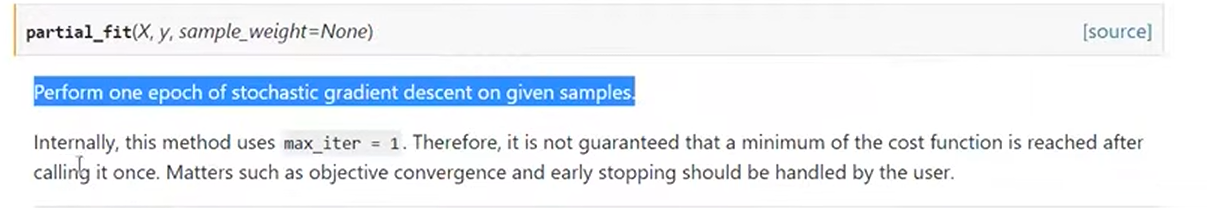

In [271]:
batch_size = 35 
for i in range(100):
    idx = random.sample(range(X_train.shape[0]),batch_size)
    sgd.partial_fit(X_train[idx],y_train[idx])

In [272]:
sgd.coef_

array([  54.12289273,  -79.67225857,  323.71901049,  238.46077759,
         21.29443177,  -21.35324761, -164.29943276,  131.53937372,
        305.94147325,  126.12542195])

In [273]:
sgd.intercept_

array([144.25906926])

In [274]:
y_pred =sgd.predict(X_test)

In [275]:
r2_score(y_test,y_pred)

0.4188038603474258

In [276]:
# change values of eta0 and see the changes in the model